## Penalized Regression: Ridge and LASSO

So far we have approached feature selection---that is, selection of which ${\bf X}$ variables to based our predictions on---by considering several subsets of features and comparing scores. But what if we want to consider *all* of the features? We don't necessarily want to select all the features to include in our model, because we run the risk of overfitting to the training data. But maybe we want to *consider* every feature for selection rather than just a few subsets. Penalized regression is one way of performing de facto feature selection: throw all the available features into the model and let the model fitting sort out which to include.

In [55]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import make_column_selector, ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import cross_val_score
from sklearn.metrics import r2_score

We'll use the Ames housing data. We'll do a little cleaning first to:

- Drop a few columns that have mostly missing values
- Drop a few rows with missing values
- Drop the ID columns (row order and PID)

In [56]:
ames = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/main/data/AmesHousing.txt", sep="\t")

# Get rid of columns with mostly NaN values
good_cols = ames.isna().sum() < 100
ames = ames.loc[:,good_cols]

# Drop other NAs
ames = ames.dropna()

# drop ID columns and put target in y
X = ames.drop(["SalePrice", "Order", "PID"], axis = 1)
y = ames["SalePrice"]

X

,MS SubClass,MS Zoning,Lot Area,Street,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,...,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition
0,20,RL,31770,Pave,IR1,Lvl,AllPub,Corner,Gtl,NAmes,...,62,0,0,0,0,0,5,2010,WD,Normal
1,20,RH,11622,Pave,Reg,Lvl,AllPub,Inside,Gtl,NAmes,...,0,0,0,120,0,0,6,2010,WD,Normal
2,20,RL,14267,Pave,IR1,Lvl,AllPub,Corner,Gtl,NAmes,...,36,0,0,0,0,12500,6,2010,WD,Normal
3,20,RL,11160,Pave,Reg,Lvl,AllPub,Corner,Gtl,NAmes,...,0,0,0,0,0,0,4,2010,WD,Normal
4,60,RL,13830,Pave,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,...,34,0,0,0,0,0,3,2010,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,80,RL,7937,Pave,IR1,Lvl,AllPub,CulDSac,Gtl,Mitchel,...,0,0,0,0,0,0,3,2006,WD,Normal
2926,20,RL,8885,Pave,IR1,Low,AllPub,Inside,Mod,Mitchel,...,0,0,0,0,0,0,6,2006,WD,Normal
2927,85,RL,10441,Pave,Reg,Lvl,AllPub,Inside,Gtl,Mitchel,...,32,0,0,0,0,700,7,2006,WD,Normal
2928,20,RL,10010,Pave,Reg,Lvl,AllPub,Inside,Mod,Mitchel,...,38,0,0,0,0,0,4,2006,WD,Normal


In [57]:
y

0       215000
1       105000
2       172000
3       244000
4       189900
         ...  
2925    142500
2926    131000
2927    132000
2928    170000
2929    188000
Name: SalePrice, Length: 2821, dtype: int64

Let's try a linear regression model first. We'll standardize numerical predictors and dummify categorical predictors.

In [58]:
ct = ColumnTransformer(
  [
    ("dummify",
    OneHotEncoder(sparse_output = False, handle_unknown='ignore'),
    make_column_selector(dtype_include=object)),
    ("standardize",
    StandardScaler(),
    make_column_selector(dtype_include=np.number))
  ],
  remainder = "passthrough"
).set_output(transform="pandas")

In [59]:
lr_pipeline = Pipeline(
  [("preprocessing", ct),
  ("linear_regression", LinearRegression())]
)

In [60]:
lr_pipeline.fit(X, y)

,steps,"[('preprocessing', ...), ('linear_regression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('dummify', ...), ('standardize', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


Now let's use cross-validation to evaluate based on $R^2$.

In [61]:
cross_val_score(lr_pipeline, X, y, cv = 10, scoring = 'r2')

array([0.88433686, 0.90316706, 0.87507511, 0.91216037, 0.82269502, 0.73890838, 0.86879893, 0.63798647, 0.90277443, 0.90350125])

Hmmm... linear regression on all the predictors does not seem as bad as the textbook suggests, though there is considerably variability between the scores based on the different folds.

Let's add second degree polynomial terms for all numerical predictors and see what happens.

In [62]:
numeric_poly = Pipeline([
    ("polynomial_features", PolynomialFeatures(degree=2)),
    ("standardize", StandardScaler())
])

ct_poly = ColumnTransformer(
    [
        ("dummify",
         OneHotEncoder(sparse_output=False, handle_unknown="ignore"),
         make_column_selector(dtype_include=object)),

        ("numeric_poly",
         numeric_poly,
         make_column_selector(dtype_include=np.number))
    ],
    remainder="drop"
).set_output(transform="pandas")

In [63]:
poly_pipeline = Pipeline(
  [("preprocessing", ct_poly),
  ("linear_regression", LinearRegression())]
)

In [64]:
poly_pipeline.fit(X, y)

,steps,"[('preprocessing', ...), ('linear_regression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('dummify', ...), ('numeric_poly', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [65]:
cross_val_score(poly_pipeline, X, y, cv = 10, scoring = 'r2')

array([  0.88322049,  -0.2351045 ,  -5.18937935,   0.23576715, -25.57250551,   0.65934136,   0.23955858,  -1.0532801 ,  -3.71975499, -51.70824866])

OK, now that's bad. The moral is that just throwing in all the predictors might fit the training data well but can be pretty terrible when it comes to making predictions for new observations. We want to be more selective without having to laboriously search through many possible subsets of predictors. With 67 predictors there are $2^{67}\approx 10^{20}$ possible subsets---even before we consider polynomial terms, interactions, transformations, etc---so it would be impossible to fit every possible subset.

Instead, we include all predictors but "penalize" variables that don't contribute much to the model. Before getting to the penalty we'll consider some motivating conceptual questions.

1. Consider a simple linear regression of sale price on a single variable like living area. What is the process by which the coefficient for living area is determined? How does "least squares" work? **DISCUSS**

Least squares determines the living-area coefficient and intercept by finding the line that minimizes the sum of squared residuals. Each residual is the difference between a house’s actual sale price and its predicted price. Squaring prevents positive and negative errors from canceling and gives larger errors more weight.

2. Now consider a multiple of regression on living area and number of bedrooms, without standardizing variables. How does least squares work in this case? **DISCUSS**

With living area and number of bedrooms, least squares chooses the intercept and both slopes together to minimize the sum of squared residuals. The living-area slope represents its relationship with predicted price while holding bedrooms constant, and the bedroom slope represents its relationship with predicted price while holding living area constant.

3. If you fit the linear model, without standarizing variables, how do you interpret the coefficients for living area and number of bedrooms? What is their rough order of magnitude? Can we determine directly from the coefficients which variable the predicted prices are more sensitive to? **DISCUSS**

Without standardization, the living-area coefficient measures the predicted dollar change per additional square foot, holding bedrooms constant. The bedroom coefficient measures the predicted dollar change per additional bedroom, holding living area constant. Their scales might be tens or hundreds of dollars per square foot versus thousands or tens of thousands per bedroom, but actual values require fitting the model. We cannot directly compare their magnitudes to rank sensitivity because the predictors use different units.

4. If you standardize the variables first, how would you interpret the model coefficients? How could you determine, roughly, which variable the predicted prices are more sensitive to? **DISCUSS**

When the predictors are standardized, each coefficient measures the predicted dollar change for a one-standard-deviation increase in that predictor, holding the other predictors constant. Comparing absolute coefficient values roughly indicates which predictor produces a larger predicted change for a typical increase. This describes predictive sensitivity rather than causal importance.

5. If we want to make the predictions *less* sensitive to a particular standardized variable, what in principle should we do to its coefficient? **DISCUSS**

To make predictions less sensitive to a standardized variable, reduce the absolute value of its coefficient by moving it closer to zero. A smaller coefficient means that the same change in the predictor produces a smaller change in predicted sale price.

6. If we want to make the predictions *not at all* sensitive to a particular standardized variable, what in principle should we do to its coefficient? **DISCUSS**

To make predictions completely insensitive to a variable, set its coefficient to exactly zero. The variable then contributes nothing to the prediction, assuming it does not also appear in other terms such as interactions or squared terms.

7. Why does including a penalty like in ridge regression or LASSO "shrink" coefficients towards 0? **DISCUSS**

Ridge and LASSO shrink coefficients because they minimize training squared error plus a penalty on coefficient size. Moving coefficients toward zero reduces the penalty, so the model may accept a slightly worse training fit to obtain a smaller overall objective. Ridge generally produces smaller coefficients, while LASSO can set coefficients exactly to zero.

8. Why is it important to standarize variables when using a penalty? **DISCUSS**

Standardization matters because coefficient size depends on the predictor’s units. Changing living area from square feet to thousands of square feet changes its coefficient and therefore its penalty, even though the underlying relationship is unchanged. Standardization puts predictors on comparable scales so their units do not arbitrarily determine how strongly they are penalized.

9. What happens if the penalty parameter $\lambda$ is 0? **DISCUSS**

When \(\lambda=0\), the penalty disappears, and the objective becomes ordinary least squares. The model chooses coefficients solely to minimize training squared error, without charging anything for large coefficients.

10. What happens as the penalty parameter $\lambda$ gets larger and larger? **DISCUSS**

As \(\lambda\) increases, the penalty receives more weight and the coefficients move toward zero. Moderate shrinkage may reduce overfitting, but excessive shrinkage causes underfitting. With an unpenalized intercept, predictions approach the training mean sale price. LASSO can reach exact zero coefficients at a finite penalty, while Ridge generally approaches zero gradually.

11. Why do we not penalize the intercept? **DISCUSS**

We do not penalize the intercept because it sets the overall level of predictions rather than sensitivity to a predictor. Penalizing it would pull the baseline prediction toward zero, even when zero dollars is inappropriate. When the predictors are centered, the unpenalized intercept equals the training mean sale price.

12. Assume $\lambda = 1$. Suppose a standardized predictor has a small coefficient, say $\beta = 0.1$. How much does that coefficient add to the LASSO penalty versus the ridge penalty? If the coefficient were reduced from 0.1 to 0, how much would each penalty decrease? Which penalty offers a larger payoff for eliminating a small coefficient entirely? **DISCUSS**

When \(\lambda=1\) and \(\beta=0.1\), the coefficient adds \(1|0.1|=0.1\) to the LASSO penalty and \(1(0.1)^2=0.01\) to the Ridge penalty. Reducing the coefficient to zero decreases the penalties by 0.1 and 0.01, respectively. LASSO therefore offers ten times the penalty reduction for eliminating this small coefficient, although the final choice also depends on the resulting increase in prediction error.

- Ridge regression shrinks all coefficient estimates toward zero but typically keeps every predictor in the model.
- LASSO regression shrinks coefficients and can set some exactly to zero, automatically removing those predictors.
- Choose ridge when predictors are highly correlated and you think many of them contain useful predictive information. Ridge tends to share influence among correlated variables.
- Choose LASSO when you want a simpler, more interpretable model with automatic variable selection.
- With highly correlated predictors, LASSO may keep one and drop the others—sometimes somewhat arbitrarily—while ridge usually retains all of them with smaller coefficients.
- Both methods are useful when there are many predictors or when ordinary least squares may overfit.

**Note that in scikit-learn the penalty parameter $\lambda$ is called `alpha`.**

## Ridge Regression

Let's fit regression regression first.

In [66]:
ridge_pipeline = Pipeline(
  [("preprocessing", ct),
  ("ridge_regression", Ridge(alpha=1))]
)

In [67]:
ridge_pipeline.fit(X, y)

,steps,"[('preprocessing', ...), ('ridge_regression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('dummify', ...), ('standardize', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [68]:
cross_val_score(ridge_pipeline, X, y, cv = 10, scoring = 'r2')

array([0.88714414, 0.90234101, 0.87838221, 0.92163172, 0.8345624 , 0.74313152, 0.86135562, 0.68453605, 0.91776347, 0.90466508])

There are a lot of predictors so there are a lot of coefficients. The code below is just an illustration of how the coefficients in the ridge regression model compare to the original linear regression model.

In [69]:
coef_compare = pd.DataFrame()
coef_compare["feature"] = lr_pipeline.named_steps["preprocessing"].get_feature_names_out()

coef_compare["lr"] = lr_pipeline.named_steps['linear_regression'].coef_
coef_compare["ridge"] = ridge_pipeline.named_steps['ridge_regression'].coef_
coef_compare["diff"] = abs(coef_compare["lr"]) - abs(coef_compare["ridge"])

In [70]:
coef_compare.sort_values(by = "diff", ascending=False)

,feature,lr,ridge,diff
91,dummify__Roof Matl_ClyTile,-559653.342134,-233156.089658,326497.252476
93,dummify__Roof Matl_Membran,119504.966230,32582.552859,86922.413371
94,dummify__Roof Matl_Metal,109059.255835,28387.663156,80671.592679
37,dummify__Neighborhood_GrnHill,127054.304996,66530.685838,60523.619159
69,dummify__Condition 2_RRAe,64910.291903,24567.527777,40342.764126
...,...,...,...,...
9,dummify__Lot Shape_IR2,3714.571039,7298.885203,-3584.314165
45,dummify__Neighborhood_NoRidge,23073.438286,27838.034970,-4764.596685
46,dummify__Neighborhood_NridgHt,17323.198503,22416.699195,-5093.500692
111,dummify__Exterior 1st_Stucco,-609.269882,-5946.929666,-5337.659785


Let's add a ridge penalty to the polynomial regression

In [71]:
ridge_poly_pipeline = Pipeline(
  [("preprocessing", ct_poly),
  ("ridge_regression", Ridge(alpha=1))]
)

In [72]:
ridge_poly_pipeline.fit(X, y)

,steps,"[('preprocessing', ...), ('ridge_regression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('dummify', ...), ('numeric_poly', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [73]:
cross_val_score(ridge_poly_pipeline, X, y, cv = 10, scoring = 'r2')

array([ 0.91643374,  0.91589548,  0.52803531,  0.84083074,  0.78663152,  0.68627357,  0.85705628, -0.04182712,  0.419092  ,  0.83885314])

In [74]:
poly_coef_compare = pd.DataFrame()

poly_coef_compare["feature"] = poly_pipeline.named_steps["preprocessing"].get_feature_names_out()

poly_coef_compare["lr_poly"] = poly_pipeline.named_steps["linear_regression"].coef_
poly_coef_compare["ridge_poly"] = ridge_poly_pipeline.named_steps["ridge_regression"].coef_

poly_coef_compare["diff_poly"] = (
    poly_coef_compare["lr_poly"].abs()
    - poly_coef_compare["ridge_poly"].abs()
)

In [75]:
poly_coef_compare.sort_values(by = "diff_poly", ascending=False)

,feature,lr_poly,ridge_poly,diff_poly
794,numeric_poly__Garage Cars Yr Sold,3.387006e+06,-4620.485750,3.382386e+06
244,numeric_poly__Garage Cars,-3.245972e+06,-5390.912549,3.240581e+06
834,numeric_poly__3Ssn Porch Yr Sold,-3.033907e+06,2595.063963,3.031312e+06
804,numeric_poly__Garage Area Yr Sold,-2.974090e+06,-4376.452692,2.969713e+06
245,numeric_poly__Garage Area,2.798078e+06,-4469.165800,2.793609e+06
...,...,...,...,...
51,dummify__Neighborhood_Somerst,1.597666e+03,6782.704918,-5.185039e+03
46,dummify__Neighborhood_NridgHt,3.863365e+03,9412.370927,-5.549006e+03
334,numeric_poly__Overall Qual Gr Liv Area,5.111578e+03,11990.016265,-6.878439e+03
739,numeric_poly__Bedroom AbvGr 3Ssn Porch,7.009193e+03,14597.269287,-7.588076e+03


## LASSO

Now let's try LASSO

In [76]:
lasso_pipeline = Pipeline(
  [("preprocessing", ct),
  ("lasso_regression", Lasso(alpha=1))]
)

In [77]:
lasso_pipeline.fit(X, y)

,steps,"[('preprocessing', ...), ('lasso_regression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('dummify', ...), ('standardize', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [78]:
cross_val_score(lasso_pipeline, X, y, cv = 10, scoring = 'r2')

C:\Users\sammy\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.029e+09, tolerance: 1.571e+09
  model = cd_fast.enet_coordinate_descent(
C:\Users\sammy\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.337e+09, tolerance: 1.603e+09
  model = cd_fast.enet_coordinate_descent(
C:\Users\sammy\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.271e+10, toleranc

array([0.88518658, 0.90350535, 0.87598015, 0.91272267, 0.84018431, 0.74897011, 0.87210755, 0.6385441 , 0.90335199, 0.91467053])

In [79]:
coef_compare["lasso"] = lasso_pipeline.named_steps['lasso_regression'].coef_
coef_compare["ridge_lasso_diff"] = abs(coef_compare["ridge"]) - abs(coef_compare["lasso"])

In [80]:
coef_compare.sort_values(by = "ridge_lasso_diff", ascending=False)

,feature,lr,ridge,diff,lasso,ridge_lasso_diff
126,dummify__Exterior 2nd_PreCast,37584.951869,25708.646790,11876.305079,623.765038,25084.881752
98,dummify__Roof Matl_WdShngl,118966.036255,83910.181360,35055.854896,58830.723632,25079.457727
96,dummify__Roof Matl_Tar&Grv,61103.839805,24715.717943,36388.121863,12.313931,24703.404012
95,dummify__Roof Matl_Roll,55399.766568,16828.505080,38571.261487,-987.398326,15841.106754
92,dummify__Roof Matl_CompShg,47815.565877,26802.263636,21013.302241,-11572.161484,15230.102152
...,...,...,...,...,...,...
68,dummify__Condition 2_PosN,-113384.181772,-77996.160321,35388.021451,-111624.851127,-33628.690806
69,dummify__Condition 2_RRAe,64910.291903,24567.527777,40342.764126,60878.855589,-36311.327812
109,dummify__Exterior 1st_PreCast,37584.951869,25708.646790,11876.305079,76167.305679,-50458.658888
37,dummify__Neighborhood_GrnHill,127054.304996,66530.685838,60523.619159,132015.733845,-65485.048008


How many ridge coefficients are 0?

In [81]:
(coef_compare["ridge"] == 0).sum()

np.int64(0)

How many LASSO coefficients are 0?

In [82]:
(coef_compare["lasso"] == 0).sum()

np.int64(25)

Let's add a lasso penalty to the polynomial regression

In [83]:
lasso_poly_pipeline = Pipeline(
  [("preprocessing", ct_poly),
  ("lasso_regression", Lasso(alpha=1))]
)

In [84]:
lasso_poly_pipeline.fit(X, y)

C:\Users\sammy\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.198e+11, tolerance: 1.793e+09
  model = cd_fast.enet_coordinate_descent(


,steps,"[('preprocessing', ...), ('lasso_regression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('dummify', ...), ('numeric_poly', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [85]:
cross_val_score(lasso_poly_pipeline, X, y, cv = 10, scoring = 'r2')

C:\Users\sammy\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.800e+11, tolerance: 1.633e+09
  model = cd_fast.enet_coordinate_descent(
C:\Users\sammy\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.591e+11, tolerance: 1.507e+09
  model = cd_fast.enet_coordinate_descent(
C:\Users\sammy\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.875e+11, toleranc

array([ 0.90979667,  0.92702486,  0.44652545,  0.78533568,  0.77909959,  0.82331629,  0.85113281, -0.85238606, -0.07422078,  0.86454442])

In [86]:
poly_coef_compare["lasso_poly"] = lasso_poly_pipeline.named_steps["lasso_regression"].coef_

poly_coef_compare["ridge_lasso_diff_poly"] = (
    poly_coef_compare["ridge_poly"].abs()
    - poly_coef_compare["lasso_poly"].abs()
)

In [87]:
poly_coef_compare.sort_values(by = "ridge_lasso_diff_poly", ascending=False)

,feature,lr_poly,ridge_poly,diff_poly,lasso_poly,ridge_lasso_diff_poly
126,dummify__Exterior 2nd_PreCast,46508.615317,26111.675137,20396.940180,1934.238609,24177.436528
302,numeric_poly__Lot Area Gr Liv Area,-26349.340528,-22033.486849,4315.853679,458.529117,21574.957732
330,numeric_poly__Overall Qual Total Bsmt SF,44213.087678,27183.859599,17029.228079,9036.333895,18147.525704
769,numeric_poly__TotRms AbvGrd Misc Val,48926.675238,15902.289844,33024.385394,-3821.078063,12081.211781
334,numeric_poly__Overall Qual Gr Liv Area,5111.577635,11990.016265,-6878.438630,-0.000000,11990.016265
...,...,...,...,...,...,...
94,dummify__Roof Matl_Metal,15115.740454,10325.802612,4789.937841,45438.678668,-35112.876056
100,dummify__Exterior 1st_AsphShn,-45377.934301,-13686.992691,31690.941610,-49426.340005,-35739.347314
223,numeric_poly__Overall Qual,-61342.056277,-3803.537261,57538.519016,40803.262534,-36999.725273
109,dummify__Exterior 1st_PreCast,46508.615318,26111.675137,20396.940181,95628.406450,-69516.731313


How many ridge coefficients are 0?

In [88]:
(poly_coef_compare["ridge_poly"] == 0).sum()

np.int64(4)

How many LASSO coefficients are 0?

In [89]:
(poly_coef_compare["lasso_poly"] == 0).sum()

np.int64(52)

## Grid search on `alpha` parameter

Note that useful values of `alpha` to consider depend on the scale of the $y$ variable.

In [90]:
from sklearn.model_selection import GridSearchCV

lasso_pipeline = Pipeline(
  [("preprocessing", ct),
  ("lasso_regression", Lasso(alpha = 1))]
).set_output(transform="pandas")

alphas = {'lasso_regression__alpha': np.array([10000, 1000, 100, 10, 1])}

gscv = GridSearchCV(lasso_pipeline, param_grid=alphas, cv = 10, scoring='r2')

In [91]:
gscv_fitted = gscv.fit(X, y)

gscv_fitted.cv_results_

C:\Users\sammy\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.029e+09, tolerance: 1.571e+09
  model = cd_fast.enet_coordinate_descent(
C:\Users\sammy\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.337e+09, tolerance: 1.603e+09
  model = cd_fast.enet_coordinate_descent(
C:\Users\sammy\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.271e+10, toleranc

{'mean_fit_time': array([0.03995986, 0.04221246, 0.1134366 , 0.11670823, 0.33830385]),
 'std_fit_time': array([0.00279348, 0.00100946, 0.00542501, 0.0227033 , 0.06912214]),
 'mean_score_time': array([0.01070368, 0.01032422, 0.01004119, 0.01023667, 0.01055162]),
 'std_score_time': array([0.00071433, 0.00051801, 0.00043093, 0.00040112, 0.00033383]),
 'param_lasso_regression__alpha': masked_array(data=[10000, 1000, 100, 10, 1],
              mask=[False, False, False, False, False],
        fill_value=999999),
 'params': [{'lasso_regression__alpha': np.int64(10000)},
  {'lasso_regression__alpha': np.int64(1000)},
  {'lasso_regression__alpha': np.int64(100)},
  {'lasso_regression__alpha': np.int64(10)},
  {'lasso_regression__alpha': np.int64(1)}],
 'split0_test_score': array([0.77315012, 0.86355064, 0.89380717, 0.89168592, 0.88518658]),
 'split1_test_score': array([0.74147501, 0.87197583, 0.90424468, 0.90485654, 0.90350535]),
 'split2_test_score': array([0.73671146, 0.81703649, 0.88225665,

In [92]:
df_cv_results_ = pd.DataFrame(gscv_fitted.cv_results_)

df_cv_results_

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_lasso_regression__alpha,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,split5_test_score,split6_test_score,split7_test_score,split8_test_score,split9_test_score,mean_test_score,std_test_score,rank_test_score
0,0.039960,0.002793,0.010704,0.000714,10000,{'lasso_regression__alpha': 10000},0.773150,0.741475,0.736711,0.792426,0.727367,0.672488,0.769420,0.649719,0.810124,0.763664,0.743654,0.047894,5
1,0.042212,0.001009,0.010324,0.000518,1000,{'lasso_regression__alpha': 1000},0.863551,0.871976,0.817036,0.914216,0.835060,0.708880,0.831613,0.660023,0.913971,0.855617,0.827194,0.078337,4
2,0.113437,0.005425,0.010041,0.000431,100,{'lasso_regression__alpha': 100},0.893807,0.904245,0.882257,0.928612,0.866778,0.750009,0.857909,0.675012,0.922320,0.907350,0.858830,0.077964,1
3,0.116708,0.022703,0.010237,0.000401,10,{'lasso_regression__alpha': 10},0.891686,0.904857,0.878866,0.917118,0.850546,0.753422,0.872547,0.646129,0.907051,0.916983,0.853920,0.083110,2
4,0.338304,0.069122,0.010552,0.000334,1,{'lasso_regression__alpha': 1},0.885187,0.903505,0.875980,0.912723,0.840184,0.748970,0.872108,0.638544,0.903352,0.914671,0.849522,0.084405,3


## Elastic Net

- Elastic net combines ridge and LASSO penalties, so it both shrinks coefficients and can set some coefficients exactly to zero.
- It is often preferred when you want variable selection but also have strongly correlated predictors.
- Unlike LASSO, elastic net tends to keep correlated predictors together rather than choosing one and discarding the others.
- It has two tuning choices: the overall penalty strength and the balance between ridge-like shrinkage and LASSO-like variable selection.
- Think of it as a middle ground: ridge keeps all predictors, LASSO selects a sparse subset, and elastic net can select groups of useful predictors while dropping clearly unhelpful ones.

In [93]:
elastic_pipeline = Pipeline(
  [("preprocessing", ct),
  ("elastic_net", ElasticNet(alpha=1, l1_ratio=0.5))]
)

In [94]:
cross_val_score(elastic_pipeline, X, y, cv = 10, scoring = 'r2')

array([0.85554118, 0.84071839, 0.85482838, 0.88754895, 0.85075165, 0.72374365, 0.80725486, 0.66306372, 0.89132019, 0.84737846])

In [95]:
elastic_pipeline.fit(X, y)

,steps,"[('preprocessing', ...), ('elastic_net', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('dummify', ...), ('standardize', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Elastic Net: Grid search

In [96]:
elastic_pipeline_1 = Pipeline(
  [("preprocessing", ct),
  ("elastic_net", ElasticNet())]
).set_output(transform="pandas")

param_grid = {
    "elastic_net__alpha": [1, 10, 100],
    "elastic_net__l1_ratio": np.arange(0.0, 1.2, 0.2),
}

gscv = GridSearchCV(elastic_pipeline_1, param_grid=param_grid, cv = 5, scoring='r2')

In [97]:
gscv_fitted = gscv.fit(X, y)

gscv_fitted.cv_results_

C:\Users\sammy\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.919e+12, tolerance: 1.348e+09
Linear regression models with a zero l1 penalization strength are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(
C:\Users\sammy\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.089e+12, tolerance: 1.474e+09
Linear regression models with a zero l1 penalization strength are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV 

{'mean_fit_time': array([0.4160274 , 0.04537387, 0.04309902, 0.04515781, 0.05042381, 0.32541175, 0.40750747, 0.03500624, 0.03261089, 0.03447404, 0.03660564, 0.12270403, 0.4183291 ,
        0.03130755, 0.03292947, 0.03354778, 0.03285961, 0.10946932]),
 'std_fit_time': array([0.00377603, 0.00586171, 0.000674  , 0.00140038, 0.00208471, 0.04921707, 0.00716438, 0.00098604, 0.00053032, 0.00189822, 0.00139824, 0.0468987 , 0.00615908,
        0.00077537, 0.00094338, 0.00054117, 0.00062615, 0.0060437 ]),
 'mean_score_time': array([0.01293368, 0.01239891, 0.0116981 , 0.01197   , 0.01204953, 0.01209631, 0.01290483, 0.01261106, 0.01164107, 0.0120472 , 0.01296172, 0.01329546, 0.01280575,
        0.01132512, 0.01235275, 0.0122221 , 0.01168795, 0.01325655]),
 'std_score_time': array([0.00027009, 0.00096854, 0.00037351, 0.00042396, 0.00065732, 0.00043083, 0.00039431, 0.00046   , 0.00030276, 0.00043694, 0.00097571, 0.00053582, 0.00068388,
        0.00045198, 0.00069068, 0.00038408, 0.00031701, 0.001965

In [98]:
df_cv_results_ = pd.DataFrame(gscv_fitted.cv_results_)

df_cv_results_

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_elastic_net__alpha,param_elastic_net__l1_ratio,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.416027,0.003776,0.012934,0.000270,1,0.0,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.819310,0.873470,0.775538,0.734519,0.857822,0.812132,0.051506,8
1,0.045374,0.005862,0.012399,0.000969,1,0.2,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.830470,0.881659,0.778866,0.739074,0.866618,0.819337,0.053523,7
2,0.043099,0.000674,0.011698,0.000374,1,0.4,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.842222,0.890269,0.781719,0.743712,0.876022,0.826789,0.055902,6
3,0.045158,0.001400,0.011970,0.000424,1,0.6,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.854984,0.899709,0.784092,0.748899,0.886498,0.834836,0.058726,5
4,0.050424,0.002085,0.012050,0.000657,1,0.8,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.869985,0.910922,0.786466,0.756417,0.899221,0.844602,0.061939,4
5,0.325412,0.049217,0.012096,0.000431,1,1.0,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.897744,0.910938,0.796918,0.774262,0.905899,0.857152,0.059018,3
6,0.407507,0.007164,0.012905,0.000394,10,0.0,"{'elastic_net__alpha': 10, 'elastic_net__l1_ra...",0.492511,0.578344,0.541161,0.505391,0.563972,0.536276,0.032954,13
7,0.035006,0.000986,0.012611,0.000460,10,0.2,"{'elastic_net__alpha': 10, 'elastic_net__l1_ra...",0.543978,0.630330,0.587613,0.549154,0.615216,0.585258,0.034473,12
8,0.032611,0.000530,0.011641,0.000303,10,0.4,"{'elastic_net__alpha': 10, 'elastic_net__l1_ra...",0.605470,0.690470,0.640126,0.598959,0.674490,0.641903,0.036319,11
9,0.034474,0.001898,0.012047,0.000437,10,0.6,"{'elastic_net__alpha': 10, 'elastic_net__l1_ra...",0.679356,0.759111,0.697470,0.654039,0.742257,0.706446,0.039030,10


In [99]:
y_pred = gscv_fitted.predict(X)

In [100]:
target = pd.DataFrame()

target["actual"] = y
target["predicted"] = y_pred

target

,actual,predicted
0,215000,218388.243679
1,105000,117726.828123
2,172000,65809.498269
3,244000,274770.257070
4,189900,179516.735946
...,...,...
2925,142500,158534.160801
2926,131000,138474.266725
2927,132000,107452.537001
2928,170000,176715.713297


<Axes: xlabel='actual', ylabel='predicted'>

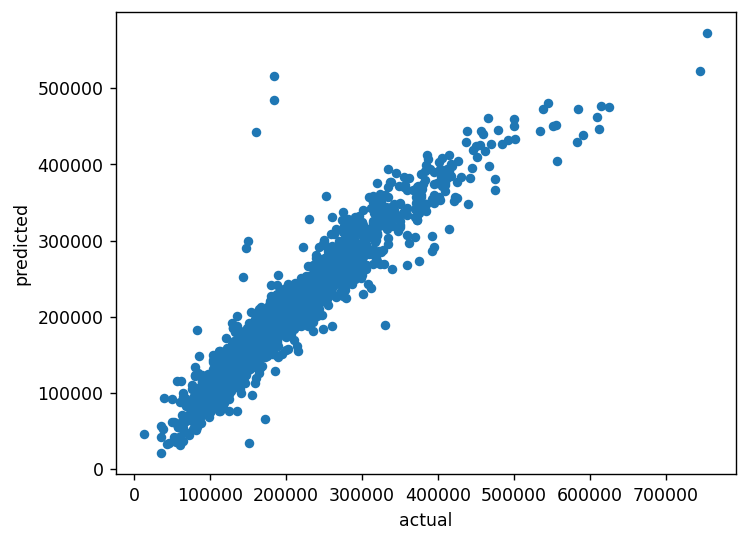

In [101]:
target.plot.scatter(x = "actual", y = "predicted")

## Practice Activity

## Loans Data

The loans data set represents thousands of loans made through the Lending Club platform, which is a platform that allows individuals to lend to other individuals. Of course, not all loans are created equal. Someone who is a essentially a sure bet to pay back a loan will have an easier time getting a loan with a low interest rate than someone who appears to be riskier. And for people who are very risky? They may not even get a loan offer, or they may not have accepted the loan offer due to a high interest rate. It is important to keep that last part in mind, since this dataset only represents loans actually made, i.e. do not mistake this data for loan applications!

[Some information about the data set is here](https://openintrostat.github.io/openintro/reference/loans_full_schema.html). There are also some related exercises in this [OpenIntro textbook](https://openintro-ims.netlify.app/inf-model-mlr.html).

**Our goal will be to develop a regression model for predicting `interest_rate`.**

We will have a competition to see who can come up with the model with the smallest test RMSE. Fit several models and try to find the smallest test RMSE. When you think you have a good one, share your model and its test RMSE. Then see what other people have done; can you do even better?

**Previously you considered selected subsets of features. Now you should try, Ridge, LASSO, and elastic net.**

You should use `GridSearchCV` to tune at least one parameter.

Note: you should do some exploration of the data first before you start fitting models.

In [102]:
df = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/refs/heads/main/data/loans_full_schema.csv")

df

,Unnamed: 0,emp_title,emp_length,state,homeownership,annual_income,verified_income,debt_to_income,annual_income_joint,verification_income_joint,...,sub_grade,issue_month,loan_status,initial_listing_status,disbursement_method,balance,paid_total,paid_principal,paid_interest,paid_late_fees
0,1,global config engineer,3.0,NJ,MORTGAGE,90000.0,Verified,18.01,NaN,NaN,...,C3,Mar-2018,Current,whole,Cash,27015.86,1999.33,984.14,1015.19,0.0
1,2,warehouse office clerk,10.0,HI,RENT,40000.0,Not Verified,5.04,NaN,NaN,...,C1,Feb-2018,Current,whole,Cash,4651.37,499.12,348.63,150.49,0.0
2,3,assembly,3.0,WI,RENT,40000.0,Source Verified,21.15,NaN,NaN,...,D1,Feb-2018,Current,fractional,Cash,1824.63,281.80,175.37,106.43,0.0
3,4,customer service,1.0,PA,RENT,30000.0,Not Verified,10.16,NaN,NaN,...,A3,Jan-2018,Current,whole,Cash,18853.26,3312.89,2746.74,566.15,0.0
4,5,security supervisor,10.0,CA,RENT,35000.0,Verified,57.96,57000.0,Verified,...,C3,Mar-2018,Current,whole,Cash,21430.15,2324.65,1569.85,754.80,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,owner,10.0,TX,RENT,108000.0,Source Verified,22.28,NaN,NaN,...,A4,Jan-2018,Current,whole,Cash,21586.34,2969.80,2413.66,556.14,0.0
9996,9997,director,8.0,PA,MORTGAGE,121000.0,Verified,32.38,NaN,NaN,...,D3,Feb-2018,Current,whole,Cash,9147.44,1456.31,852.56,603.75,0.0
9997,9998,toolmaker,10.0,CT,MORTGAGE,67000.0,Verified,45.26,107000.0,Source Verified,...,E2,Feb-2018,Current,fractional,Cash,27617.65,4620.80,2382.35,2238.45,0.0
9998,9999,manager,1.0,WI,MORTGAGE,80000.0,Source Verified,11.99,NaN,NaN,...,A1,Feb-2018,Current,whole,Cash,21518.12,2873.31,2481.88,391.43,0.0


In [103]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline


In [104]:
# Use the original seed so the simulated data are reproducible.
rng = np.random.default_rng(5544)
n = 60
stores = pd.DataFrame({
    "traffic": rng.normal(800, 200, n), "ads": rng.normal(300, 100, n),
    "size": rng.normal(1800, 400, n), "income": rng.normal(65, 12, n),
    "competitors": rng.integers(0, 6, n)
})


In [105]:
# Seats shares information with size; tenure has no true effect in this simulation.
stores["seats"] = stores["size"] / 30 + rng.normal(0, 4, n)
stores["tenure"] = rng.normal(5, 3, n)
sales = (6 * stores["traffic"] + 5 * stores["ads"] + 2 * stores["size"]
         + 60 * stores["income"] - 400 * stores["competitors"]
         + rng.normal(0, 2800, n))


In [106]:
# Hand-picked demonstration penalties, not CV-selected values.
# Ridge and LASSO use different loss scaling, so their alphas are not comparable.
fits = {
    "least squares": make_pipeline(StandardScaler(), LinearRegression()),
    "ridge": make_pipeline(StandardScaler(), Ridge(alpha=10)),
    "LASSO": make_pipeline(StandardScaler(), Lasso(alpha=300))
}


In [107]:
# Fit each pipeline and store coefficients on the standardized predictor scale.
coefs = pd.DataFrame(index=stores.columns)
for name, pipe in fits.items():
    pipe.fit(stores, sales)
    coefs[name] = pipe[-1].coef_
coefs.round(0) + 0.0


,least squares,ridge,LASSO
traffic,1667.0,1418.0,1289.0
ads,449.0,342.0,87.0
size,347.0,219.0,0.0
income,1401.0,1200.0,1042.0
competitors,-753.0,-637.0,-409.0
seats,234.0,223.0,106.0
tenure,-141.0,-157.0,0.0


In [108]:
# Count exact zeros using the unrounded coefficients.
# A coefficient that rounds to zero is not necessarily exactly zero.
(coefs == 0).sum()


least squares    0
ridge            0
LASSO            2
dtype: int64